# 公開時点の情報で、公開後の再生数を予測する（LightGBM・SHAP）

- **問い**：動画を出す前にわかる情報だけで、公開後の再生数をどこまで当てられるか。何が効くか
- **目的変数**：log(1＋公開後の再生数)。動画ごとの日次は上位24本しかないため、**公開から7日以上たった動画の累計**を使う。Shorts は上位13本すべてで累計の99%以上が7日以内に来ており「≒7日の再生数」。長尺は7日以降も伸びる（7日で累計の1〜94%）ので、長尺は「累計」と読む
- **特徴量（公開時点でわかるものだけ）**：種類（Shorts）、長さ、公開の曜日、直前の投稿からの日数（全体・同じ種類）、同じ日の投稿本数、タイトルの文字数・絵文字・「#shorts」、チャンネル開始からの日数。**再生数・CTR・インプレッションなど公開後の数値は入れない**。公開の時刻は書き出しにないため使えない
- **検証**：公開日順に並べた TimeSeriesSplit（5分割、過去で学習→未来を予測）。LightGBM を、中央値と重回帰のベースラインと RMSE で比べる

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, re, shap, lightgbm as lgb, statsmodels.api as sm
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression
import matplotlib; matplotlib.rcParams['font.family'] = 'Noto Sans CJK JP'
CUTOFF = pd.Timestamp('2026-10-15')
v = pd.read_csv('../data/raw/2026-10-15_videos.csv').iloc[1:].copy()
v['公開日'] = pd.to_datetime(v['動画公開時刻'], format='%b %d, %Y')
title = v['動画のタイトル'].astype(str)
v = v[~title.str.contains('LIVE') & (v['長さ'] > 0)].copy(); title = v['動画のタイトル'].astype(str)
v['Shorts'] = (v['長さ'] <= 60).astype(int)
v = v.sort_values(['公開日', 'コンテンツ']).reset_index(drop=True); title = v['動画のタイトル'].astype(str)
X = pd.DataFrame({
    'Shorts': v['Shorts'],
    'log長さ': np.log1p(v['長さ']),
    '曜日': v['公開日'].dt.dayofweek,
    '土日': (v['公開日'].dt.dayofweek >= 5).astype(int),
    '前の投稿からの日数': v['公開日'].diff().dt.days.fillna(0),
    '同じ種類の前の投稿からの日数': v.groupby('Shorts')['公開日'].diff().dt.days.fillna(0),
    '同じ日の投稿本数': v.groupby('公開日')['コンテンツ'].transform('size'),
    'タイトル文字数': title.str.len(),
    '絵文字あり': title.apply(lambda s: int(bool(re.search('[\U0001F300-\U0001FAFF\u2600-\u27BF]', s)))),
    '#shortsあり': title.str.contains('#shorts', case=False).astype(int),
    '開始からの日数': (v['公開日'] - v['公開日'].min()).dt.days,
})
y = np.log1p(v['視聴回数'].astype(float))
keep = (v['公開日'] <= CUTOFF - pd.Timedelta(days=7)) & v['視聴回数'].notna()
keep = keep.values
X, y, v = X[keep].reset_index(drop=True), y[keep].reset_index(drop=True), v[keep].reset_index(drop=True)
print(len(v), '本（Shorts', int(v.Shorts.sum()), '・長尺', int((1 - v.Shorts).sum()), '）', v['公開日'].min().date(), '〜', v['公開日'].max().date())
X.describe().T[['mean', 'min', 'max']].round(2)

/sessions/rcw-01lrui9f731ngrcihujuvacq/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


299 本（Shorts 174 ・長尺 125 ） 2026-07-18 〜 2026-10-08


,mean,min,max
Shorts,0.58,0.00,1.00
log長さ,5.65,2.48,10.67
曜日,2.94,0.00,6.00
土日,0.28,0.00,1.00
前の投稿からの日数,0.27,0.00,1.00
同じ種類の前の投稿からの日数,0.52,0.00,7.00
同じ日の投稿本数,4.08,1.00,5.00
タイトル文字数,62.88,27.00,100.00
絵文字あり,0.54,0.00,1.00
#shortsあり,0.58,0.00,1.00


## 1. 時系列 CV で比べる

In [2]:
LGB = dict(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=10, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=0)
LIN = ['Shorts', 'log長さ', '土日', '前の投稿からの日数', '同じ種類の前の投稿からの日数', '同じ日の投稿本数', 'タイトル文字数', '絵文字あり', '#shortsあり', '開始からの日数']
rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
rows, oof = [], pd.DataFrame(index=X.index, columns=['中央値', '重回帰', 'LightGBM'], dtype=float)
for k, (tr, te) in enumerate(TimeSeriesSplit(n_splits=5).split(X)):
    p = {'中央値': np.full(len(te), y[tr].median()),
         '重回帰': LinearRegression().fit(X.loc[tr, LIN], y[tr]).predict(X.loc[te, LIN]),
         'LightGBM': lgb.LGBMRegressor(**LGB).fit(X.loc[tr], y[tr]).predict(X.loc[te])}
    for m, pr in p.items(): oof.loc[te, m] = pr; rows.append((k + 1, v['公開日'][te].min().date(), len(tr), len(te), m, rmse(y[te], pr)))
cv = pd.DataFrame(rows, columns=['fold', 'テスト開始', '学習本数', 'テスト本数', 'モデル', 'RMSE'])
tab = cv.pivot(index=['fold', 'テスト開始', '学習本数', 'テスト本数'], columns='モデル', values='RMSE')[['中央値', '重回帰', 'LightGBM']]
te_all = oof.dropna().index
tab.loc[('全体', '', '', len(te_all)), :] = [rmse(y[te_all], oof.loc[te_all, m]) for m in tab.columns]
tab.round(3)

,,,モデル,中央値,重回帰,LightGBM
fold,テスト開始,学習本数,テスト本数,,,
1,2026-08-07,54,49,1.429,1.444,1.160
2,2026-08-24,103,49,1.577,1.373,1.300
3,2026-09-04,152,49,1.536,1.223,1.187
4,2026-09-15,201,49,1.235,1.132,1.496
5,2026-09-26,250,49,1.547,1.119,1.270
全体,,,245,1.470,1.265,1.288


In [3]:
by = pd.DataFrame({m: [rmse(y[te_all][v.Shorts[te_all] == s], oof.loc[te_all][v.Shorts[te_all] == s][m]) for s in (1, 0)] for m in oof.columns}, index=['Shorts', '長尺']).round(3)
print('種類別の RMSE（テスト期間全体）'); by

種類別の RMSE（テスト期間全体）


,中央値,重回帰,LightGBM
Shorts,1.406,1.335,1.358
長尺,1.581,1.128,1.150


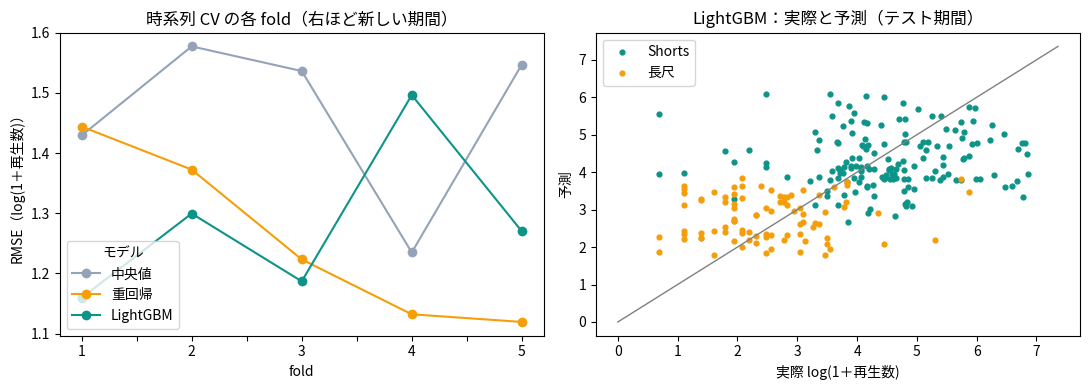

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tab.iloc[:-1].reset_index().plot(x='fold', y=['中央値', '重回帰', 'LightGBM'], marker='o', ax=ax[0], color=['#94a3b8', '#f59e0b', '#0d9488'])
ax[0].set_ylabel('RMSE（log(1＋再生数)）'); ax[0].set_title('時系列 CV の各 fold（右ほど新しい期間）')
for s, c in ((1, '#0d9488'), (0, '#f59e0b')):
    i = te_all[v.Shorts[te_all] == s]; ax[1].scatter(y[i], oof.loc[i, 'LightGBM'], s=12, c=c, label='Shorts' if s else '長尺')
lim = [0, y.max() + .5]; ax[1].plot(lim, lim, color='grey', lw=1); ax[1].legend()
ax[1].set_xlabel('実際 log(1＋再生数)'); ax[1].set_ylabel('予測'); ax[1].set_title('LightGBM：実際と予測（テスト期間）')
plt.tight_layout(); plt.savefig('../images/e06_cv.png', dpi=150); plt.show()

## 2. SHAP で効いている特徴量と、重回帰の係数の向き

In [5]:
full = lgb.LGBMRegressor(**LGB).fit(X, y)
sv = shap.TreeExplainer(full).shap_values(X)
imp = pd.Series(np.abs(sv).mean(0), index=X.columns).sort_values(ascending=False)
# SHAP の向き：特徴量と SHAP 値の相関の符号
dir_shap = pd.Series({c: np.sign(np.corrcoef(X[c], sv[:, i])[0, 1]) if X[c].std() > 0 else 0 for i, c in enumerate(X.columns)})
ols = sm.OLS(y, sm.add_constant(X[LIN])).fit(cov_type='HC3')
cmp = pd.DataFrame({'平均|SHAP|': imp.round(3), 'SHAP の向き': dir_shap.reindex(imp.index).map({1: '+', -1: '−', 0: '0'}),
    '重回帰の係数': ols.params.reindex(imp.index).round(3), '重回帰の p 値': ols.pvalues.reindex(imp.index).round(3)})
cmp['向きが一致'] = np.where(cmp['重回帰の係数'].isna(), '（重回帰に入れていない）', np.where(np.sign(cmp['重回帰の係数']) == dir_shap.reindex(imp.index), '○', '×'))
cmp

,平均|SHAP|,SHAP の向き,重回帰の係数,重回帰の p 値,向きが一致
log長さ,0.480,−,-0.336,0.009,○
開始からの日数,0.358,−,-0.012,0.000,○
タイトル文字数,0.224,−,-0.002,0.842,○
Shorts,0.214,+,-1.968,0.104,×
絵文字あり,0.132,+,0.237,0.157,○
同じ日の投稿本数,0.117,+,0.072,0.412,○
曜日,0.101,+,NaN,NaN,（重回帰に入れていない）
#shortsあり,0.059,+,1.250,0.139,○
同じ種類の前の投稿からの日数,0.035,−,-0.127,0.186,○
前の投稿からの日数,0.026,−,0.095,0.604,×


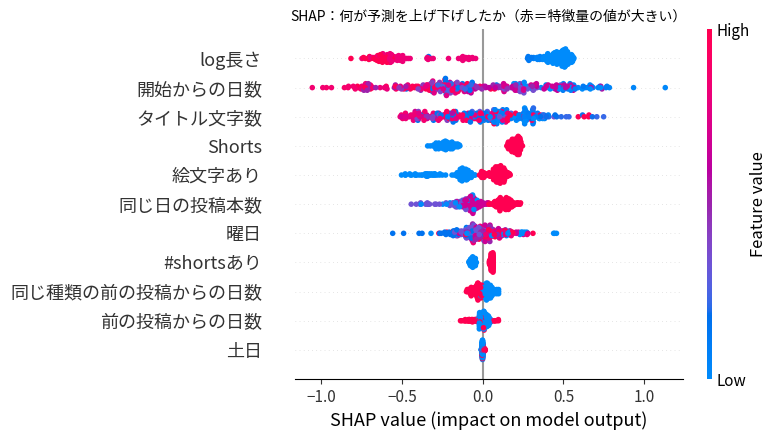

In [6]:
shap.summary_plot(sv, X, show=False, plot_size=(8, 4.5)); plt.title('SHAP：何が予測を上げ下げしたか（赤＝特徴量の値が大きい）', fontsize=10)
plt.tight_layout(); plt.savefig('../images/e06_shap.png', dpi=150); plt.show()

**読み方の注意**
- 「Shorts」「#shortsあり」「log長さ」はほぼ同じ情報（Shorts はタイトルに #shorts が付き、長さが短い）。重回帰では3つで効果を分け合うため、Shorts 単独の係数の符号は当てにならない（×はこのため）。SHAP の向きは「Shorts・短い動画ほど多い」で一致している
- 「開始からの日数」が負なのは、新しい動画ほど伸びる時間が短い（とくに長尺は7日以降も伸びる）ためでもあり、チャンネルが落ちているとは限らない

In [7]:
# Shorts だけ（目的変数がほぼ「7日の再生数」）でも同じ比較
s = v.Shorts == 1; Xs, ys = X[s].drop(columns=['Shorts', '#shortsあり']).reset_index(drop=True), y[s].reset_index(drop=True)
LINs = [c for c in LIN if c in Xs.columns]; r = {'中央値': [], '重回帰': [], 'LightGBM': []}
for tr, te in TimeSeriesSplit(n_splits=5).split(Xs):
    r['中央値'].append(rmse(ys[te], ys[tr].median())); r['重回帰'].append(rmse(ys[te], LinearRegression().fit(Xs.loc[tr, LINs], ys[tr]).predict(Xs.loc[te, LINs])))
    r['LightGBM'].append(rmse(ys[te], lgb.LGBMRegressor(**LGB).fit(Xs.loc[tr], ys[tr]).predict(Xs.loc[te])))
print(len(Xs), '本・fold 平均 RMSE', {k: round(float(np.mean(x)), 3) for k, x in r.items()})

174 本・fold 平均 RMSE {'中央値': 1.173, '重回帰': 1.222, 'LightGBM': 1.222}


## 3. 結論（3行）
1. **何が予測に効くか**：種類と長さ（Shorts・短い動画ほど再生が多い）と公開の時期でほぼ決まる。タイトルの長さ・絵文字・曜日・投稿間隔の寄与は小さく、重回帰でも有意でない
2. **どこまで当たるか**：LightGBM は中央値より RMSE が約12%小さい（1.47 → 1.29）が、重回帰（1.27）とほぼ同じ。Shorts だけで見るとどのモデルも中央値に勝てない＝Shorts 同士の差は公開前の情報では説明できない（差はサムネ・冒頭・おすすめへの乗り方など、公開後に決まる）
3. **次の動画で何を変えるか**：曜日やタイトルの長さを調整しても予測はほぼ動かないので、そこに時間をかけない。Shorts の本数を保ちつつ、公開後24時間の初速（インプレッション・視聴維持）を見て、伸びた型を次の動画に寄せる